# Clustering Methods Exercises

![Clustering.png](../asets/Clustering.png)

# Цели обучения

- Обсудить алгоритмы обучения без учителя и способы их применения
- Применять кластеризацию
- Применять снижение размерности


## Введение

Для этих упражнений мы будем использовать набор данных о качестве вина. Этот набор данных содержит различные химические характеристики вина, такие как кислотность, содержание сахара, pH и содержание алкоголя. Он также содержит показатель качества (от 3 до 9, где более высокое значение означает лучшее качество) и цвет (красное или белое). Имя файла — `Wine_Quality_Data`.

Мы будем использовать химические свойства (то есть все, кроме показателя качества и цвета) для кластеризации вин. Хотя это обучение без учителя, может быть интересно посмотреть, как результаты нашей кластеризации соотносятся с цветом и качеством.

In [1]:
from __future__ import print_function
import os
# в папке курса данные лежат в data/, у меня - в общей папке "Seturi de date"
data_path = ['data'] if os.path.isdir('data') else ['..', 'Seturi de date']

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.cluster import DBSCAN
from sklearn.cluster import AgglomerativeClustering
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score
from sklearn.model_selection import StratifiedShuffleSplit

%matplotlib inline
sns.set_style('whitegrid')

## Вопрос 1

* Импортируйте данные и проанализируйте характеристики.
* Определите, какие из них являются непрерывными, категориальными и булевыми.
* Сколько записей имеется для двух цветов вина и диапазона показателей качества?
* Постройте гистограмму показателя качества для каждого из цветов вина.

In [2]:
filepath = os.sep.join(data_path + ['Wine_Quality_Data.csv'])
data = pd.read_csv(filepath, sep=',')
print(data.shape)
data.head()

(6497, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality,color
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


Типы данных для каждой записи. Реализация алгоритма K-means в библиотеке Scikit-learn рассчитана исключительно на работу с непрерывными данными (хотя иногда её применяют и для категориальных или булевых типов). К счастью, все столбцы, которые мы будем использовать (все, кроме «quality» и «color»), являются непрерывными.

In [3]:
data.dtypes

fixed_acidity           float64
volatile_acidity        float64
citric_acid             float64
residual_sugar          float64
chlorides               float64
free_sulfur_dioxide     float64
total_sulfur_dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
color                       str
dtype: object

In [4]:
# сколько вин каждого цвета
data.color.value_counts()

color
white    4898
red      1599
Name: count, dtype: int64

In [5]:
# распределение оценок качества: всего и по цветам
print('диапазон качества:', data.quality.min(), '-', data.quality.max())
pd.crosstab(data.quality, data.color, margins=True)

диапазон качества: 3 - 9


color,red,white,All
quality,,,
3,10,20,30
4,53,163,216
5,681,1457,2138
6,638,2198,2836
7,199,880,1079
8,18,175,193
9,0,5,5
All,1599,4898,6497


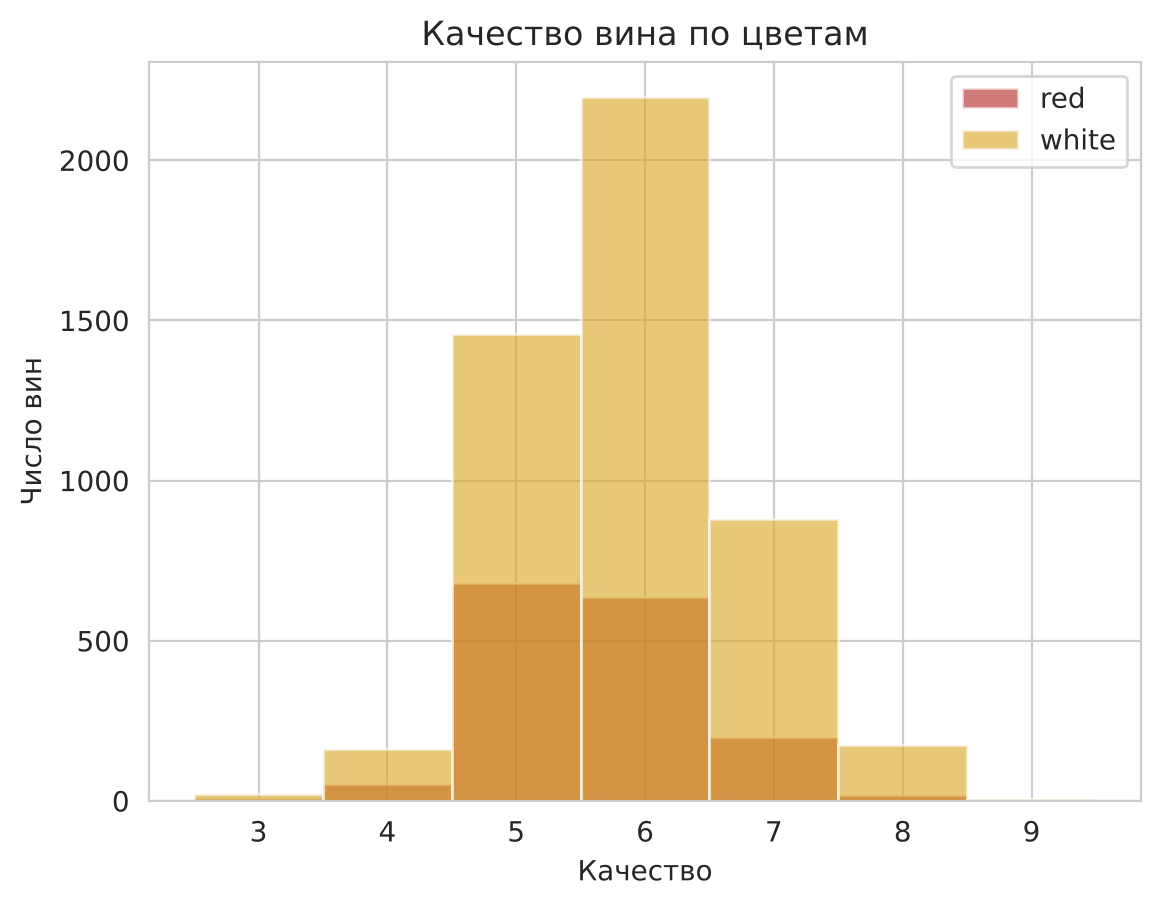

In [6]:
# гистограмма качества для каждого цвета
red, white = 'firebrick', 'goldenrod'
bins = np.arange(3, 11) - 0.5
ax = plt.axes()
for color, plot_color in zip(['red', 'white'], [red, white]):
    data.loc[data.color == color, 'quality'].plot.hist(bins=bins, alpha=0.6, ax=ax, color=plot_color, label=color)
ax.legend()
ax.set(xlabel='Качество', ylabel='Число вин', title='Качество вина по цветам');

**Ответ.**

В данных 6497 вин и 13 столбцов. 11 химических признаков (от `fixed_acidity` до `alcohol`) имеют тип `float64`, они непрерывные. `quality` это целое число от 3 до 9, по смыслу это порядковая (категориальная) оценка. `color` это строка с двумя значениями, red и white, то есть по сути булев признак.

Белых вин 4898, красных 1599, то есть белых примерно в три раза больше. Оценки качества идут от 3 до 9, но крайние встречаются редко: оценку 3 имеют 30 вин, а оценку 9 всего 5, и все они белые. Больше всего вин с оценками 5 (2138) и 6 (2836).

На гистограмме видно, что у красных вин оценки 5 и 6 встречаются почти одинаково часто (681 и 638), а у белых чаще всего 6 (2198). Высоких оценок (7 и выше) у белых заметно больше.

## Вопрос 2

* Оцените корреляцию и асимметрию соответствующих переменных — всех, кроме цвета и качества.
* Проведите необходимые преобразования признаков и/или масштабирование.
* Проанализируйте парное распределение переменных с помощью парных графиков, чтобы проверить правильность масштабирования и нормализации.


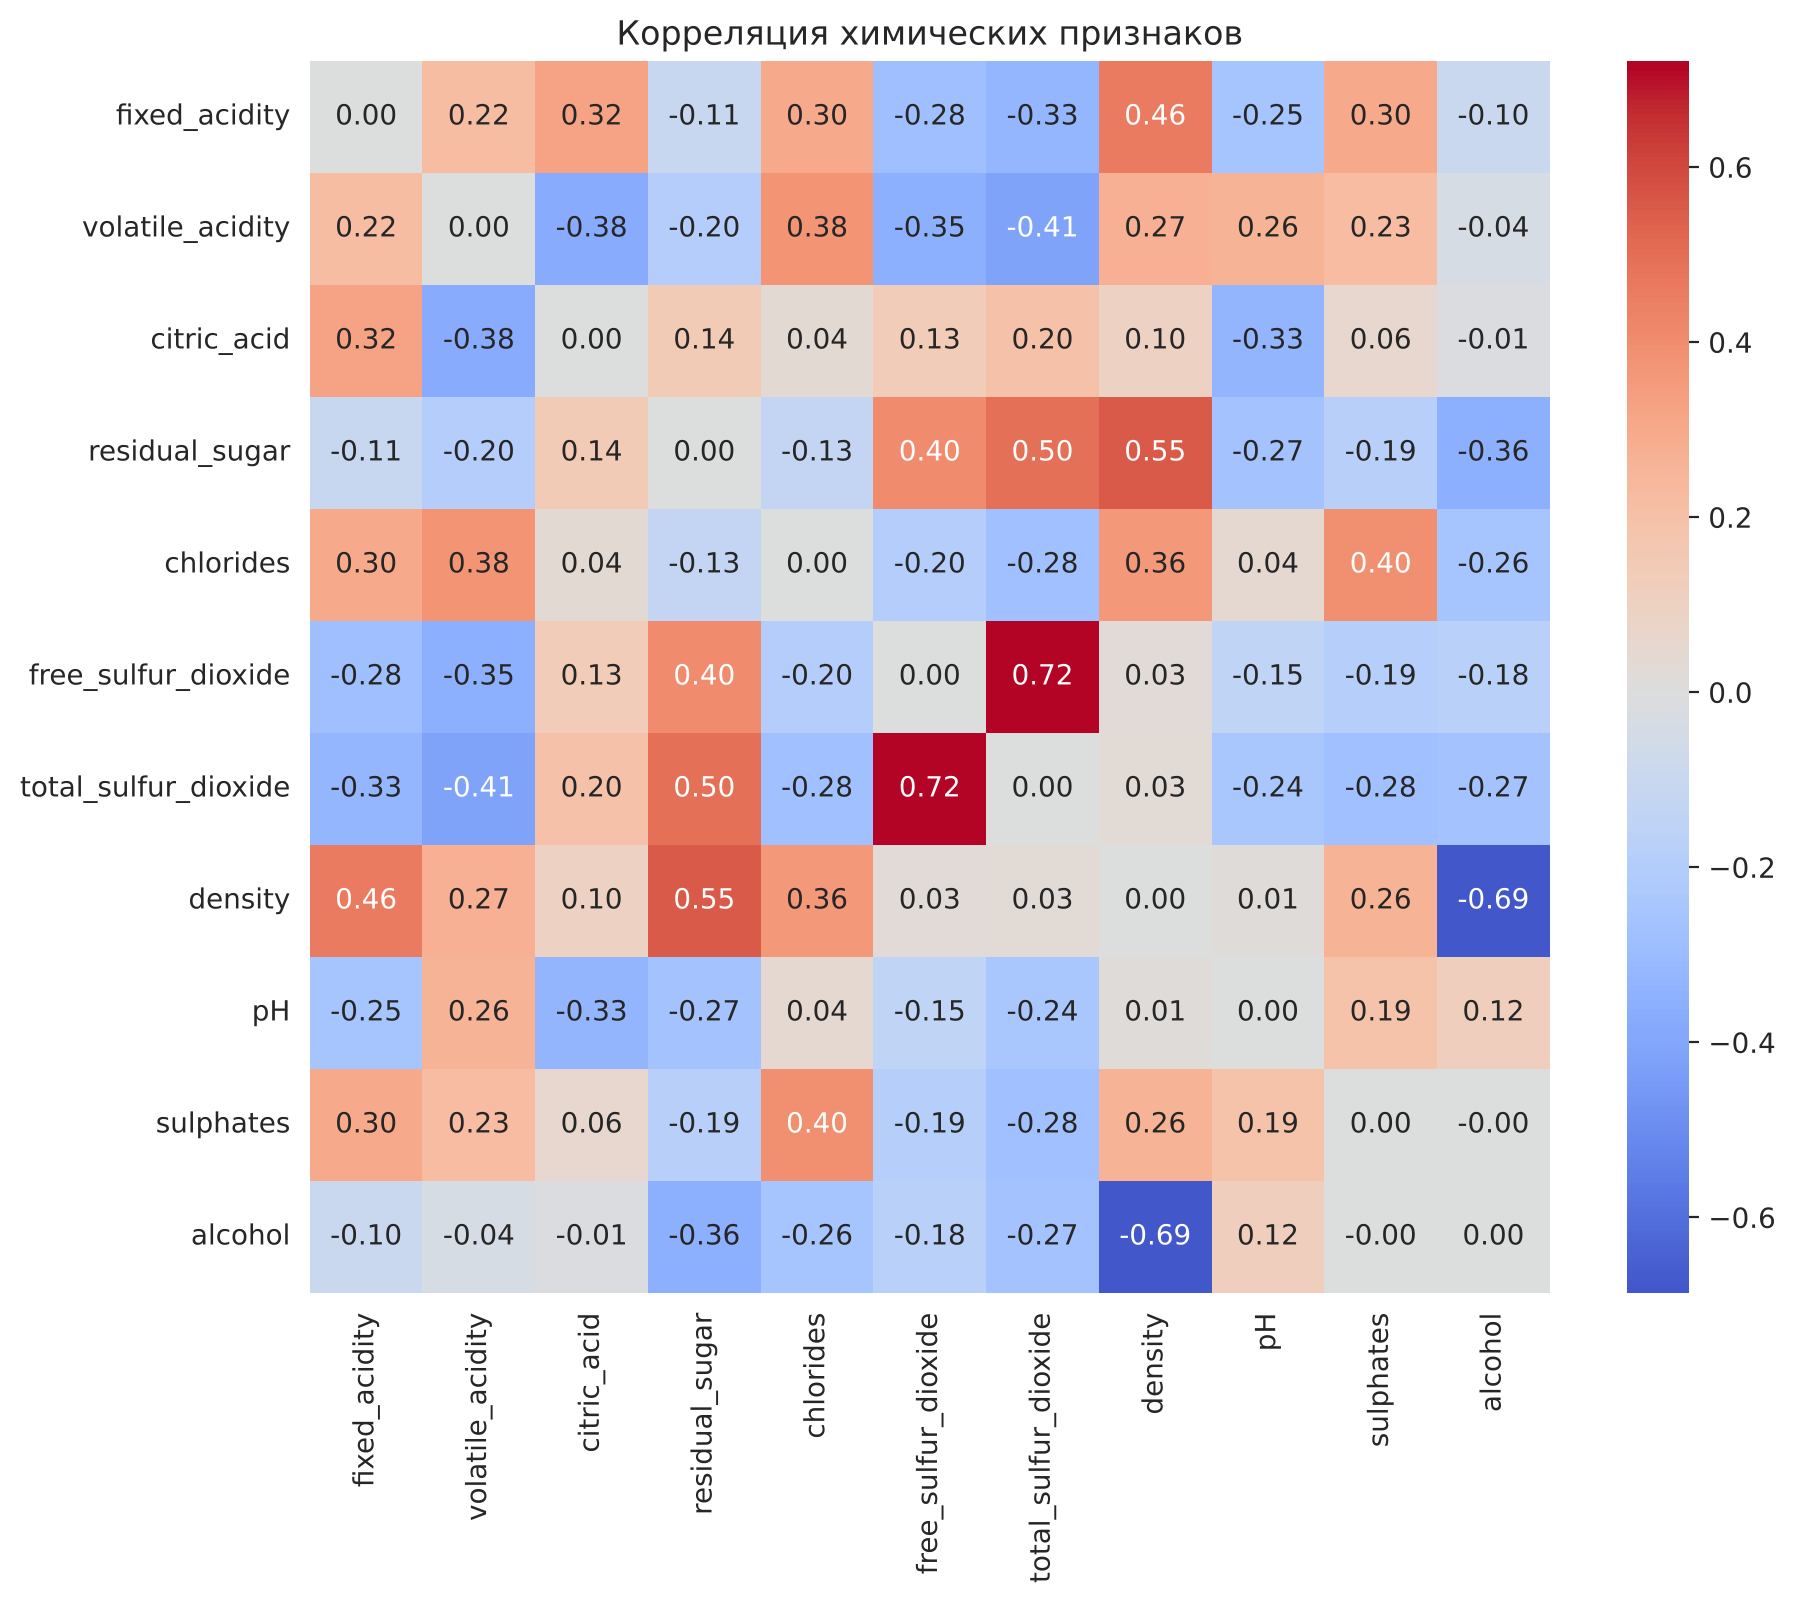

In [7]:
float_columns = [x for x in data.columns if x not in ['color', 'quality']]

# матрица корреляций, диагональ обнуляем, чтобы не мешала
corr_mat = data[float_columns].corr()
for x in range(len(float_columns)):
    corr_mat.iloc[x, x] = 0.0

plt.figure(figsize=(10, 8))
sns.heatmap(corr_mat, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Корреляция химических признаков');

In [8]:
# с каким признаком каждый коррелирует сильнее всего
pd.DataFrame({'признак': corr_mat.abs().idxmax(), 'корреляция': [corr_mat.loc[c, corr_mat.abs().idxmax()[c]] for c in corr_mat.index]}).round(3)

,признак,корреляция
fixed_acidity,density,0.459
volatile_acidity,total_sulfur_dioxide,-0.414
citric_acid,volatile_acidity,-0.378
residual_sugar,density,0.553
chlorides,sulphates,0.396
free_sulfur_dioxide,total_sulfur_dioxide,0.721
total_sulfur_dioxide,free_sulfur_dioxide,0.721
density,alcohol,-0.687
pH,citric_acid,-0.330
sulphates,chlorides,0.396


А также анализ значений асимметрии в преддверии преобразований.

In [9]:
skew_columns = data[float_columns].skew().sort_values(ascending=False)
print(skew_columns.round(3))
skew_columns = skew_columns.loc[skew_columns > 0.75]
print('\nпризнаки с асимметрией > 0.75:', list(skew_columns.index))

chlorides               5.400
sulphates               1.797
fixed_acidity           1.723
volatile_acidity        1.495
residual_sugar          1.435
free_sulfur_dioxide     1.220
alcohol                 0.566
density                 0.504
citric_acid             0.472
pH                      0.387
total_sulfur_dioxide   -0.001
dtype: float64

признаки с асимметрией > 0.75: ['chlorides', 'sulphates', 'fixed_acidity', 'volatile_acidity', 'residual_sugar', 'free_sulfur_dioxide']


In [10]:
# логарифмируем сильно скошенные признаки
for col in skew_columns.index.tolist():
    data[col] = np.log1p(data[col])
data[float_columns].skew().sort_values(ascending=False).round(3)

chlorides               4.484
volatile_acidity        1.127
sulphates               1.099
fixed_acidity           0.977
alcohol                 0.566
density                 0.504
citric_acid             0.472
residual_sugar          0.415
pH                      0.387
total_sulfur_dioxide   -0.001
free_sulfur_dioxide    -0.721
dtype: float64

In [11]:
# масштабирование: среднее 0, стандартное отклонение 1
sc = StandardScaler()
data[float_columns] = sc.fit_transform(data[float_columns])
data[float_columns].describe().loc[['mean', 'std', 'min', 'max']].round(2)

,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol
mean,-0.00,0.00,0.00,0.00,-0.00,-0.00,-0.00,-0.00,0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-3.63,-1.82,-2.19,-1.69,-1.46,-3.93,-1.94,-2.53,-3.10,-2.43,-2.09
max,5.05,5.77,9.23,3.78,13.73,3.67,5.74,14.77,4.92,7.39,3.70


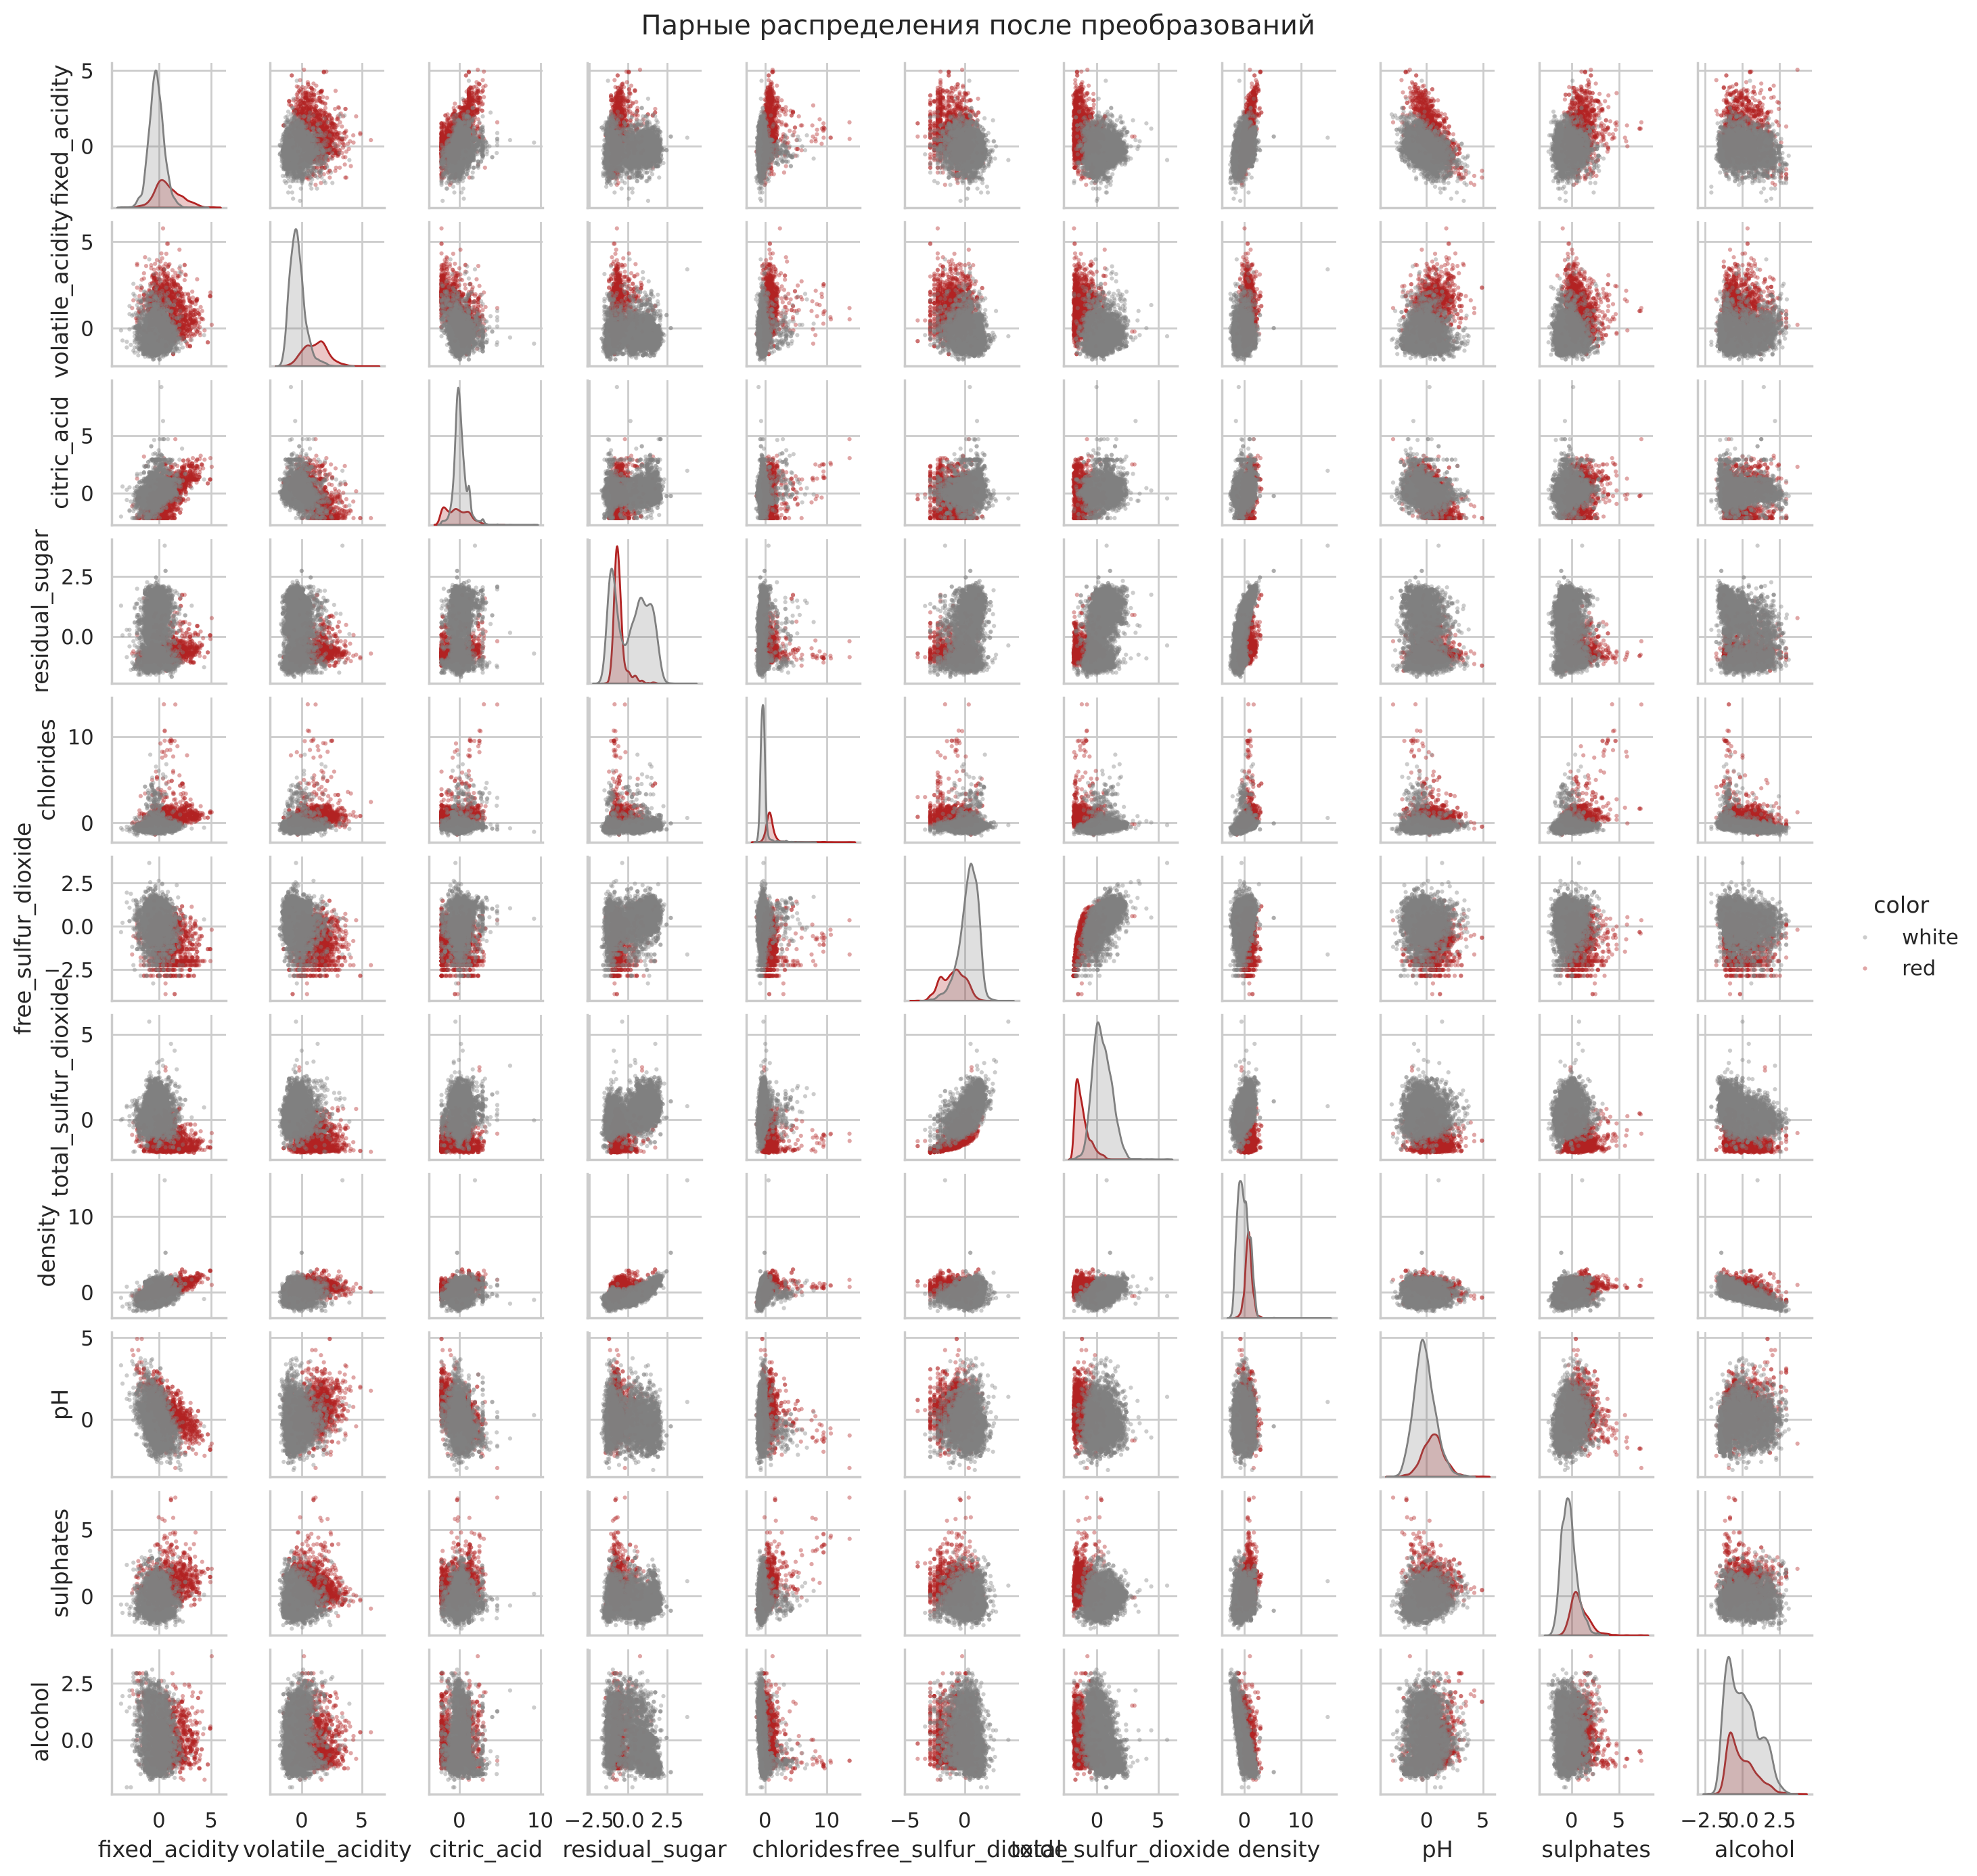

In [12]:
sns.set_context('notebook')
g = sns.pairplot(data[float_columns + ['color']], hue='color', hue_order=['white', 'red'],
                 palette={'red': red, 'white': 'gray'}, height=1.25, plot_kws=dict(s=5, alpha=0.4, linewidth=0))
g.fig.suptitle('Парные распределения после преобразований', y=1.01);

**Ответ.**

Сильнее всего связаны `free_sulfur_dioxide` и `total_sulfur_dioxide` (0.72), это понятно, свободный диоксид серы входит в общий. Дальше идут `density` и `alcohol` (-0.69, чем больше спирта, тем меньше плотность) и `residual_sugar` и `density` (0.55). Остальные корреляции слабее 0.5 по модулю, так что сильно дублирующих друг друга признаков нет и удалять ничего не нужно.

Асимметрия больше 0.75 у шести признаков: `chlorides` (5.40), `sulphates`, `fixed_acidity`, `volatile_acidity`, `residual_sugar` и `free_sulfur_dioxide`. К ним применено преобразование `log1p`. После него асимметрия стала намного меньше (у `residual_sugar` 0.42 вместо 1.44, у `sulphates` 1.10 вместо 1.80). У `chlorides` она осталась большой (4.48): значения там маленькие, меньше 1, и логарифм их почти не меняет.

После этого все 11 признаков приведены к одному масштабу через `StandardScaler`, у каждого среднее 0 и стандартное отклонение 1. Это нужно, потому что K-средних и агломеративная кластеризация считают евклидовы расстояния, и без масштабирования признак с большими числами (`total_sulfur_dioxide`) перевесил бы все остальные.

На парных графиках видно, что все признаки теперь лежат примерно в одном диапазоне. У некоторых остались выбросы (`chlorides`, `density`, `citric_acid`). Красные и белые вина заметно расходятся по `total_sulfur_dioxide` (у красных он ниже), `volatile_acidity` и `chlorides` (у красных выше), хотя цвет в преобразованиях никак не участвовал.

## Вопрос 3

* Постройте модель кластеризации методом K-средних с двумя кластерами.
* Проанализируйте кластеры по цвету вина.

In [13]:
km = KMeans(n_clusters=2, random_state=42, n_init=10)
km = km.fit(data[float_columns])
data['kmeans'] = km.predict(data[float_columns])

(data[['color', 'kmeans']]
 .groupby(['kmeans', 'color'])
 .size()
 .to_frame()
 .rename(columns={0: 'number'}))

number
kmeans color        
0      red      1576
       white      87
1      red        23
       white    4811

In [14]:
# доля вин, у которых кластер совпадает с цветом (номера кластеров произвольные, берем лучший вариант)
ct = pd.crosstab(data.color, data.kmeans)
match = max(ct.values.diagonal().sum(), ct.values[::-1].diagonal().sum())
print('совпадает с цветом: %d из %d (%.2f%%)' % (match, len(data), 100 * match / len(data)))
ct

совпадает с цветом: 6387 из 6497 (98.31%)


kmeans,0,1
color,,
red,1576,23
white,87,4811


**Ответ.**

K-средних с двумя кластерами почти точно разделил вина по цвету, хотя цвет модели не показывали. В кластер 0 попало 1576 красных и 87 белых вин, в кластер 1 попало 4811 белых и 23 красных. То есть кластер совпадает с цветом у 6387 вин из 6497, это 98.3%, не совпадает только у 110.

Получается, что главное различие в химическом составе вин это как раз различие между красными и белыми. Номера кластеров (0 и 1) при этом случайные, при другом `random_state` они могут поменяться местами.

## Вопрос 4

* Теперь постройте модели K-Means с количеством кластеров от 1 до 20.
* Для каждой модели запишите количество кластеров и значение инерции.
* Постройте график зависимости количества кластеров от инерции. Можно ли выделить какое-то идеальное количество кластеров?

In [15]:
km_list = list()
for clust in range(1, 21):
    km = KMeans(n_clusters=clust, random_state=42, n_init=10)
    km = km.fit(data[float_columns])
    km_list.append(pd.Series({'clusters': clust, 'inertia': km.inertia_, 'model': km}))

plot_data = (pd.concat(km_list, axis=1).T[['clusters', 'inertia']].set_index('clusters'))
plot_data.index = plot_data.index.astype(int)
plot_data['inertia'] = plot_data['inertia'].astype(float)
plot_data['снижение, %'] = (-plot_data.inertia.pct_change() * 100)
plot_data.round(1)

,inertia,"снижение, %"
clusters,,
1,71467.0,NaN
2,55456.0,22.4
3,45199.9,18.5
4,40674.1,10.0
5,38203.5,6.1
6,36241.9,5.1
7,34307.7,5.3
8,33037.5,3.7
9,31976.4,3.2


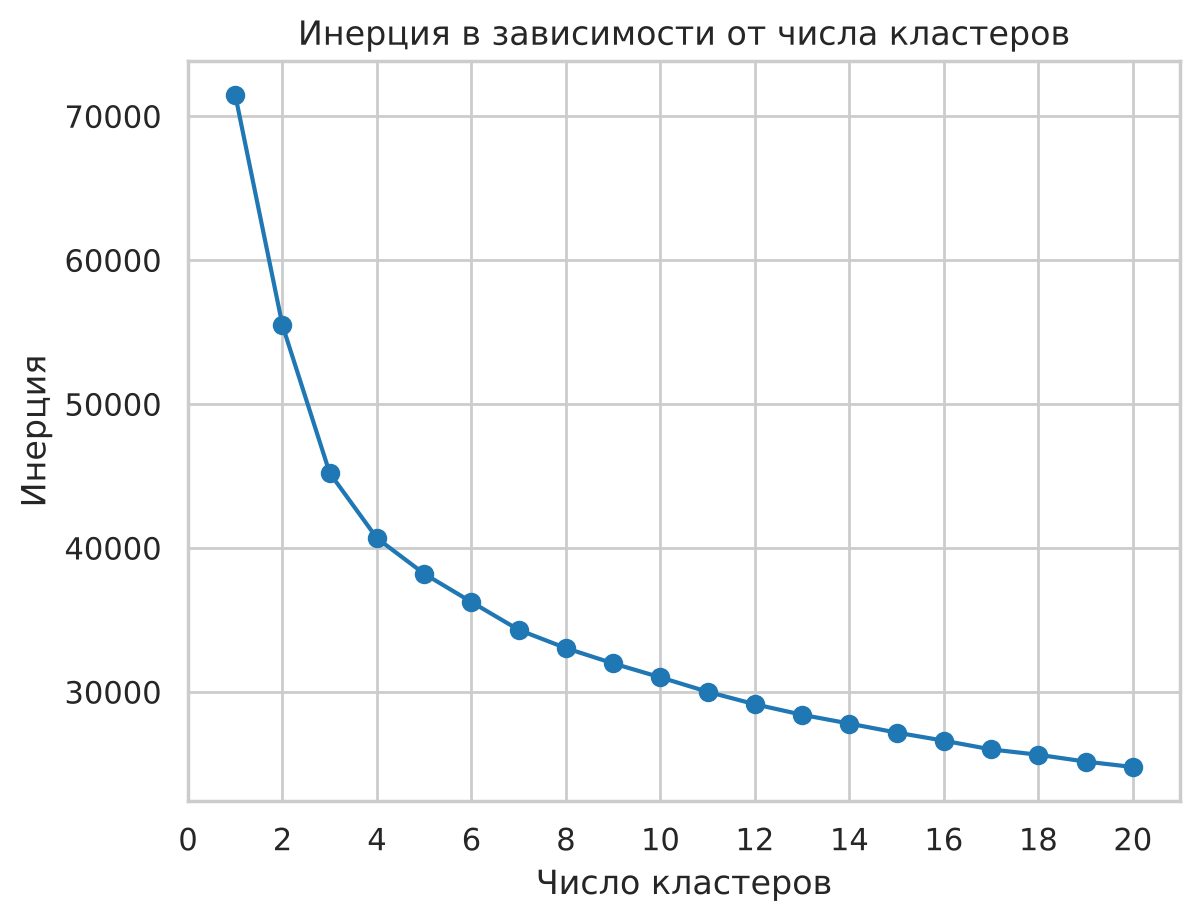

In [16]:
ax = plt.axes()
ax.plot(plot_data.index, plot_data['inertia'], marker='o', ls='-')
ax.set_xticks(range(0, 21, 2))
ax.set_xlim(0, 21)
ax.set(xlabel='Число кластеров', ylabel='Инерция', title='Инерция в зависимости от числа кластеров');

**Ответ.**

Инерция (сумма квадратов расстояний от точек до центров своих кластеров) всегда уменьшается, когда кластеров становится больше, поэтому смотреть нужно на то, где она перестает падать быстро.

При переходе от 1 к 2 кластерам инерция падает на 22.4%, от 2 к 3 на 18.5%, от 3 к 4 на 10.0%. Дальше каждое новое разбиение дает 5-6% и меньше, а после 8 кластеров около 2-3%. Резкого «локтя» на графике нет, кривая сгибается плавно. Самый заметный перегиб получается в районе 3-4 кластеров, так что по этому графику я бы выбрал 4.

Интересно, что по инерции число 2 никак не выделяется, хотя мы знаем, что в данных есть две понятные группы (красные и белые вина). То есть метод локтя дает только приблизительный ориентир, и идеального числа кластеров здесь назвать нельзя.

## Вопрос 5

* Постройте модель агломеративного кластеризации с двумя кластерами.
* Сравните полученные результаты с результатами, полученными с помощью алгоритма K-средних, с точки зрения цвета вина.
* Визуализируйте дендрограмму, построенную с помощью агломеративного кластеризации. *Подсказка:* В SciPy есть модуль [`cluster.hierarchy`](https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html#module-scipy.cluster.hierarchy), содержащий функции `linkage` и `dendrogram`, необходимые для построения карты связей и отображения полученной дендрограммы.

In [17]:
ag = AgglomerativeClustering(n_clusters=2, linkage='ward', compute_full_tree=True)
ag = ag.fit(data[float_columns])
data['agglom'] = ag.fit_predict(data[float_columns])

Обратите внимание, что распределение по кластерам является произвольным: номера основных кластеров для красного и белого цветов могут не совпадать с приведёнными ниже, а также могут различаться при использовании метода K-средних и агломеративного кластерирования.

In [18]:
# сначала агломеративная кластеризация и цвет
(data[['color', 'agglom']]
 .groupby(['color', 'agglom'])
 .size()
 .to_frame()
 .rename(columns={0: 'number'}))

number
color agglom        
red   0           31
      1         1568
white 0         4755
      1          143

In [19]:
# для сравнения: K-средних и цвет
(data[['color', 'kmeans']]
 .groupby(['color', 'kmeans'])
 .size()
 .to_frame()
 .rename(columns={0: 'number'}))

number
color kmeans        
red   0         1576
      1           23
white 0           87
      1         4811

In [20]:
# оба метода вместе
(data[['color', 'agglom', 'kmeans']]
 .groupby(['color', 'agglom', 'kmeans'])
 .size()
 .to_frame()
 .rename(columns={0: 'number'}))

number
color agglom kmeans        
red   0      0           13
             1           18
      1      0         1563
             1            5
white 0      0           38
             1         4717
      1      0           49
             1           94

In [21]:
ct_ag = pd.crosstab(data.color, data.agglom)
match_ag = max(ct_ag.values.diagonal().sum(), ct_ag.values[::-1].diagonal().sum())
print('агломеративная: совпадает с цветом %d из %d (%.2f%%)' % (match_ag, len(data), 100 * match_ag / len(data)))
print('K-средних:      совпадает с цветом %d из %d (%.2f%%)' % (match, len(data), 100 * match / len(data)))
same = pd.crosstab(data.agglom, data.kmeans)
agree = max(same.values.diagonal().sum(), same.values[::-1].diagonal().sum())
print('методы согласны между собой для %d вин (%.2f%%)' % (agree, 100 * agree / len(data)))

агломеративная: совпадает с цветом 6323 из 6497 (97.32%)
K-средних:      совпадает с цветом 6387 из 6497 (98.31%)
методы согласны между собой для 6347 вин (97.69%)


два последних объединения на расстояниях: [135.  175.1]


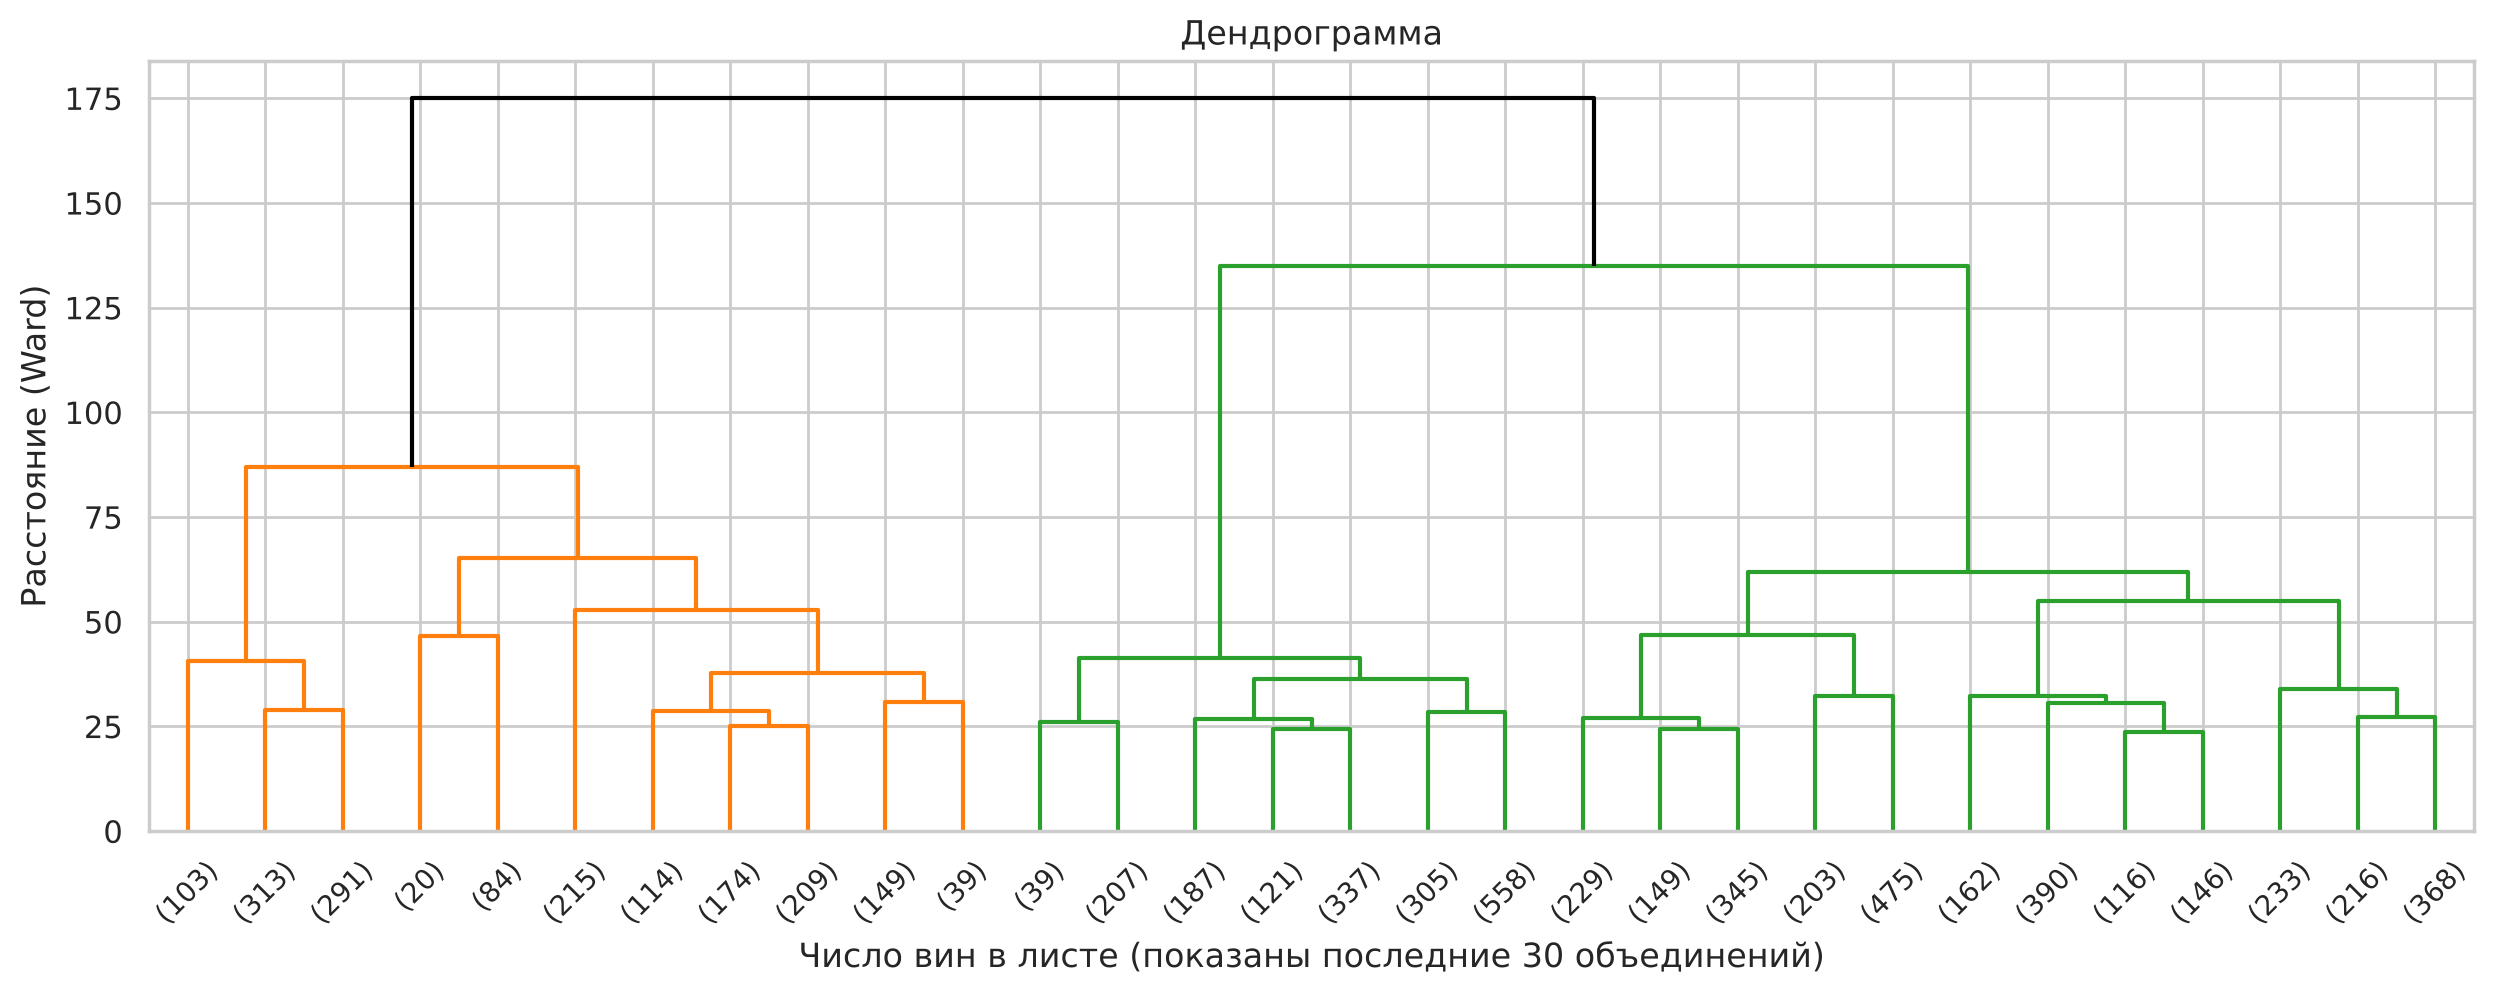

In [22]:
from scipy.cluster import hierarchy

Z = hierarchy.linkage(data[float_columns], method='ward')

fig, ax = plt.subplots(figsize=(15, 5))
den = hierarchy.dendrogram(Z, orientation='top', p=30, truncate_mode='lastp', show_leaf_counts=True,
                           ax=ax, color_threshold=150, above_threshold_color='black')
ax.set(xlabel='Число вин в листе (показаны последние 30 объединений)', ylabel='Расстояние (Ward)', title='Дендрограмма');
print('два последних объединения на расстояниях:', Z[-2:, 2].round(1))

**Ответ.**

Агломеративная кластеризация (метод Уорда) с двумя кластерами тоже в основном делит вина по цвету. В кластер 1 попало 1568 красных и 143 белых вина, в кластер 0 попало 4755 белых и 31 красное. С цветом кластер совпадает у 6323 вин (97.3%).

У K-средних результат чуть лучше: 6387 вин (98.3%). Ошибается агломеративный метод в основном на белых винах: 143 белых он отнес к «красному» кластеру, а K-средних только 87. Между собой два метода согласны для 6347 вин (97.7%). Номера кластеров у них не обязаны совпадать, у K-средних «красный» кластер получил номер 0, а у агломеративного номер 1.

На дендрограмме показаны последние 30 объединений. Самое последнее объединение происходит на расстоянии около 175, а предыдущее на 135, все остальные ниже 90. То есть два верхних кластера далеко друг от друга, и разрез на два кластера выглядит естественно. Левая ветка (1711 вин) это в основном красные вина, правая (4786 вин) в основном белые. Правая ветка на расстоянии 135 делится еще на две части, то есть среди белых вин есть две отдельные подгруппы.

## Вопрос 6

В этом вопросе мы рассмотрим кластеризацию как один из способов инженерии признаков.

* Создайте **бинарную** целевую переменную `y`, указывающую, превышает ли показатель качества значение 7 или нет.
* Создайте переменную `X_with_kmeans` на основе набора данных `data`, удалив из него столбцы «quality», «color» и «agglom». Создайте из него `X_without_kmeans`, удалив столбец «kmeans».
* Для обоих наборов данных с помощью `StratifiedShuffleSplit` с 10 разбиениями обучите 10 классификаторов Random Forest и вычислите среднее значение показателей ROC-AUC.
* Сравните средние значения показателей ROC-AUC для моделей, использующих кластеры k-средних в качестве признака, и для модели, которая их не использует.

In [23]:
y = (data['quality'] > 7).astype(int)
X_with_kmeans = data.drop(['agglom', 'color', 'quality'], axis=1)
X_without_kmeans = X_with_kmeans.drop('kmeans', axis=1)
sss = StratifiedShuffleSplit(n_splits=10, random_state=6532)
print('доля вин с качеством выше 7: %.4f (%d из %d)' % (y.mean(), y.sum(), len(y)))


def get_avg_roc_10splits(estimator, X, y):
    roc_auc_list = []
    for train_index, test_index in sss.split(X, y):
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]
        estimator.fit(X_train, y_train)
        y_scored = estimator.predict_proba(X_test)[:, 1]
        roc_auc_list.append(roc_auc_score(y_test, y_scored))
    return np.mean(roc_auc_list)


estimator = RandomForestClassifier(random_state=42)
roc_with_kmeans = get_avg_roc_10splits(estimator, X_with_kmeans, y)
roc_without_kmeans = get_avg_roc_10splits(estimator, X_without_kmeans, y)
print('Без кластера K-средних как признака: ROC-AUC = %.4f' % roc_without_kmeans)
print('С кластером K-средних как признаком:  ROC-AUC = %.4f' % roc_with_kmeans)

доля вин с качеством выше 7: 0.0305 (198 из 6497)


Без кластера K-средних как признака: ROC-AUC = 0.9152
С кластером K-средних как признаком:  ROC-AUC = 0.9090


**Ответ.**

Целевая переменная очень несбалансированная: качество выше 7 только у 198 вин из 6497 (3%). Поэтому разбиения стратифицированные, а метрика ROC-AUC, а не точность.

У случайного леса средний ROC-AUC по 10 разбиениям получился 0.9152 без столбца `kmeans` и 0.9090 с ним. То есть номер кластера как признак не помог, результат даже чуть хуже, но разница всего 0.006, это в пределах случайных колебаний.

Это ожидаемо. Кластер из двух групп почти совпадает с цветом вина, а о качестве он мало что говорит. К тому же случайный лес сам умеет делить пространство признаков на области, и кластер, полученный из тех же 11 признаков, не дает ему новой информации.

Давайте теперь выясним, влияет ли количество кластеров на это улучшение.

* Создайте базовый обучающий набор из `data`, ограничив его столбцами с числами с плавающей запятой.
* Для $n = 1, \ldots, 20$ выполните обучение алгоритма k-средних с $n$ кластерами. Примените к данным кодирование «one-hot» и добавьте их в **базовый** обучающий набор. Не добавляйте их к результатам предыдущей итерации.
* Обучите 10 моделей **логистической регрессии** и вычислите среднее значение показателя ROC-AUC.
* Постройте график средних значений показателя ROC-AUC.

In [24]:
X_basis = data[float_columns]
sss = StratifiedShuffleSplit(n_splits=10, random_state=6532)


def create_kmeans_columns(n):
    km = KMeans(n_clusters=n, random_state=42, n_init=10)
    km.fit(X_basis)
    km_col = pd.Series(km.predict(X_basis))
    km_cols = pd.get_dummies(km_col, prefix='kmeans_cluster').astype(int)
    return pd.concat([X_basis, km_cols], axis=1)


estimator = LogisticRegression(max_iter=1000)
ns = range(1, 21)
roc_auc_list = [get_avg_roc_10splits(estimator, create_kmeans_columns(n), y) for n in ns]
roc_by_n = pd.Series(roc_auc_list, index=list(ns), name='ROC-AUC')
print('без кластеров (только 11 признаков): %.4f' % get_avg_roc_10splits(estimator, X_basis, y))
roc_by_n.round(4)

без кластеров (только 11 признаков): 0.7706


1     0.7705
2     0.7697
3     0.7714
4     0.7736
5     0.7777
6     0.7726
7     0.7723
8     0.7752
9     0.7727
10    0.7867
11    0.7883
12    0.7820
13    0.7964
14    0.8000
15    0.7907
16    0.7923
17    0.8016
18    0.7913
19    0.8037
20    0.7912
Name: ROC-AUC, dtype: float64

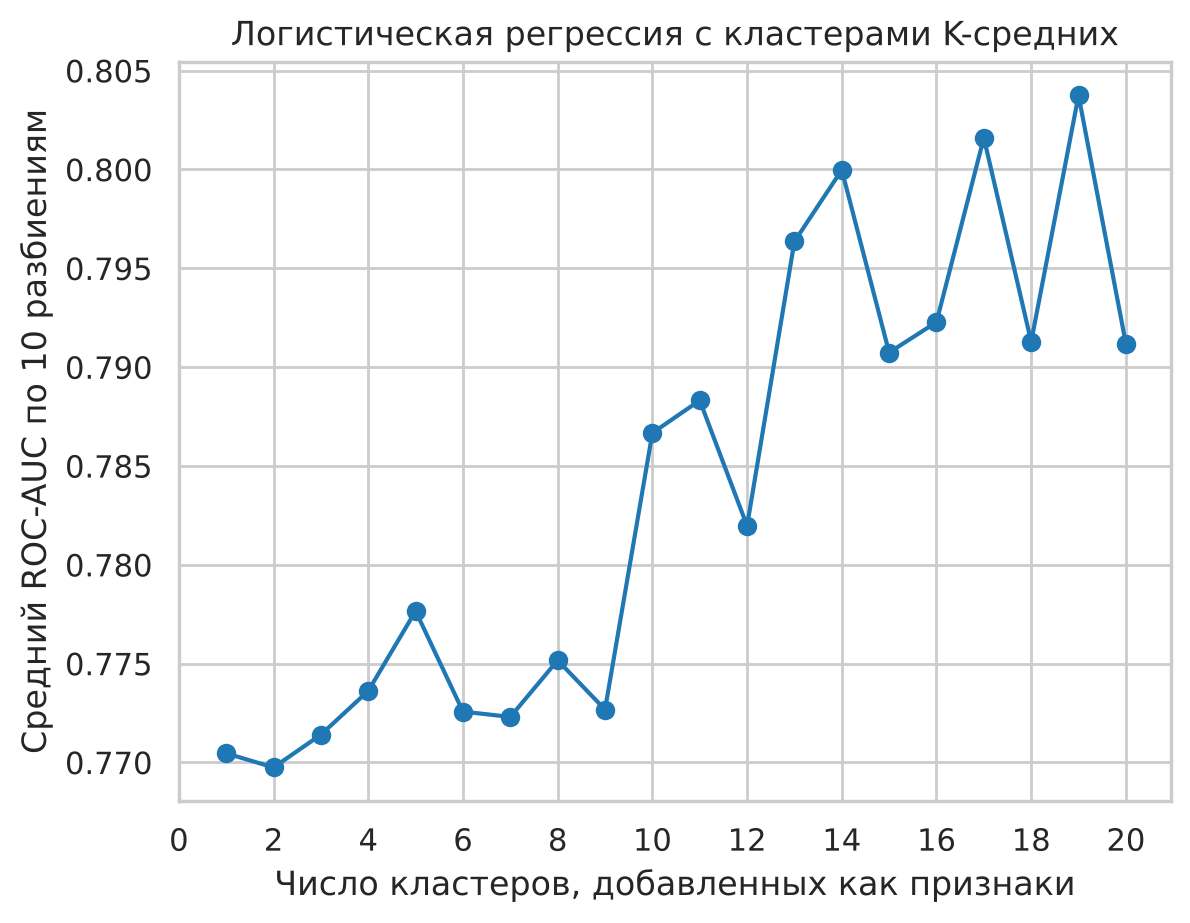

In [25]:
ax = plt.axes()
ax.plot(list(ns), roc_auc_list, marker='o')
ax.set_xticks(range(0, 21, 2))
ax.set(xlabel='Число кластеров, добавленных как признаки', ylabel='Средний ROC-AUC по 10 разбиениям',
       title='Логистическая регрессия с кластерами K-средних');
ax.grid(True)

**Ответ.**

У логистической регрессии картина другая. Без кластеров ROC-AUC равен 0.7706. С 1-9 кластерами он почти не меняется (0.770-0.778), а начиная с 10 кластеров растет: 0.787 при 10, 0.800 при 14 и максимум 0.804 при 19 кластерах. График при этом неровный (например, при 12 и 15 кластерах значение падает), потому что положение кластеров каждый раз другое, а положительных примеров мало.

Объяснение такое. Логистическая регрессия линейная и сама нелинейные зависимости не найдет. One-hot признаки кластеров говорят ей, в какой области пространства лежит вино, и для каждой области подбирается своя поправка. Чем кластеров больше, тем мельче эти области и тем лучше можно приблизить нелинейную границу.

Но даже с 19 кластерами логистическая регрессия (0.80) заметно хуже случайного леса (0.915). Так что кластеры как признаки полезны для простых линейных моделей, а моделям на деревьях они почти ничего не добавляют.